# 03 — Persistent MediaPipe pose extraction

This notebook uses the existing PyAV ingestion and V0.1 contracts, then runs one persistent MediaPipe Tasks Pose Landmarker over a local benchmark video. Raw observations are not smoothed. Normalized image coordinates and model-relative z are model estimates, not physical 3-D measurements or coaching advice.

In [1]:
from datetime import date
from pathlib import Path
import os, tempfile

import matplotlib.pyplot as plt
import mediapipe as mp
import pyarrow.parquet as pq
from IPython.display import Image, Video, display

from open_swing_analysis.contracts import CameraView, Handedness, ObservationLayer, Swing, SwingSession
from open_swing_analysis.ingestion import FrameSelection, VideoReader, ingest_video, store_ingestion_result
from open_swing_analysis.pose import MediaPipePoseBackend, MediaPipePoseConfig, extract_pose, store_pose_extraction
from open_swing_analysis.pose_video import write_annotated_video
from open_swing_analysis.storage import LocalDataStore

model_path = Path(os.environ.get('OSA_MEDIAPIPE_MODEL', '/tmp/pose_landmarker_full.task'))
sample_candidates = [
    Path(os.environ.get('OSA_GOLF_SAMPLE_VIDEO', '/missing')),
    Path('/tmp/golf-benchmark-repos/golfposepro/input videos/IMG_0758.MP4'),
    Path('/tmp/golf-benchmark-repos/heleena-golf-swing-analysis/input/Reference_Swing_DTL.mp4'),
]
sample_video = next((path for path in sample_candidates if path.is_file()), None)
assert model_path.is_file(), 'Download the documented MediaPipe task model or set OSA_MEDIAPIPE_MODEL.'
assert sample_video is not None, 'Set OSA_GOLF_SAMPLE_VIDEO to a local golf clip.'
workspace = Path(tempfile.mkdtemp(prefix='osa-pose-notebook-'))
print('MediaPipe:', mp.__version__)
print('Model:', model_path, model_path.stat().st_size, 'bytes')
print('Local sample (not copied into Git):', sample_video)
print('Temporary outputs:', workspace)

MediaPipe: 1.2.2
Model: /tmp/pose_landmarker_full.task 9398198 bytes
Local sample (not copied into Git): /tmp/golf-benchmark-repos/golfposepro/input videos/IMG_0758.MP4
Temporary outputs: /tmp/osa-pose-notebook-o88bxpqd


## Ingest and register the source

The camera view is explicitly recorded as down-the-line for this local sample. No physical rotation angle is inferred from the pixels.

In [2]:
ingestion = ingest_video(sample_video, swing_id='swing-notebook-pose-001')
session = SwingSession(
    session_id='session-notebook-pose-001', subject_id='local-benchmark-subject',
    recording_date=date(2026, 11, 4), camera_view=CameraView.DOWN_THE_LINE,
    golfer_handedness=Handedness.UNKNOWN,
    capture_metadata={'purpose': 'local pose extraction demonstration'},
)
swing = Swing(
    swing_id='swing-notebook-pose-001', session_id=session.session_id,
    video_asset_id=ingestion.asset.asset_id, club_type='unknown',
)
store = LocalDataStore(workspace / 'store')
store.write_session(session)
store.write_video_asset(session.session_id, ingestion.asset)
store.write_swing(swing)
ingestion_paths = store_ingestion_result(store, session.session_id, swing.swing_id, ingestion)
{
    'frames': ingestion.asset.frame_count,
    'dimensions': (ingestion.asset.width_px, ingestion.asset.height_px),
    'nominal_fps': ingestion.asset.nominal_fps,
    'frame_rate_mode': ingestion.asset.frame_rate_mode.value,
    'camera_view': session.camera_view.value,
    'frames_parquet': str(ingestion_paths.frames_parquet),
}

{'frames': 749,
 'dimensions': (1920, 1080),
 'nominal_fps': 30.0,
 'frame_rate_mode': 'constant',
 'camera_view': 'down_the_line',
 'frames_parquet': '/tmp/osa-pose-notebook-o88bxpqd/store/sessions/session-notebook-pose-001/swings/swing-notebook-pose-001/frames.parquet'}

## Run one persistent CPU model

MediaPipe receives monotonic integer milliseconds. The exact `Frame.timestamp_s` remains the observation timestamp; any rounding collision is separately flagged rather than written back to the source-aligned record.

In [3]:
backend = MediaPipePoseBackend(MediaPipePoseConfig(model_asset_path=model_path))
pose_result = extract_pose(
    sample_video, swing_id=swing.swing_id, frames=ingestion.frames, backend=backend,
    observation_revision='mediapipe-full-notebook-001', camera_view=session.camera_view,
)
pose_paths = store_pose_extraction(store, session.session_id, swing.swing_id, pose_result)
summary = pose_result.summary
{
    'model_version': summary.model_version,
    'frames_processed': summary.frames_processed,
    'frames_with_pose': summary.frames_with_pose,
    'pose_detection_coverage': summary.pose_detection_coverage,
    'observed_landmarks': summary.observed_landmark_count,
    'missing_landmarks': summary.missing_landmark_count,
    'mean_visibility': summary.visibility_mean,
    'total_inference_time_s': summary.total_inference_time_s,
    'mean_processing_time_ms': summary.mean_processing_time_ms,
    'timestamp_adjustments': summary.inference_timestamp_adjustment_count,
}

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1793817879.616755 1001137 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793817879.635643 1001138 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793817879.698714 1001138 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.
W0000 00:00:1793817879.698714 1001137 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


{'model_version': 'mediapipe-1.2.2;model-sha256-4eaa5eb7a9836522',
 'frames_processed': 749,
 'frames_with_pose': 749,
 'pose_detection_coverage': 1.0,
 'observed_landmarks': 24717,
 'missing_landmarks': 0,
 'mean_visibility': 0.882684623420681,
 'total_inference_time_s': 13.537437581078848,
 'mean_processing_time_ms': 18.074015462054536,
 'timestamp_adjustments': 0}

## Structured Parquet output and round trip

In [4]:
table = pq.read_table(pose_paths.observations_parquet)
round_trip = store.read_pose_observations(
    session.session_id, swing.swing_id, ObservationLayer.RAW, 'mediapipe-full-notebook-001'
)
print('Parquet rows:', table.num_rows, 'columns:', table.num_columns)
print('Schema version:', table.schema.metadata[b'schema_version'].decode())
print('Round-trip rows:', len(round_trip))
table.select(['frame_index', 'timestamp_s', 'landmark_name', 'x', 'y', 'relative_z', 'visibility', 'confidence', 'observation_status']).slice(0, 6).to_pylist()

Parquet rows: 24717 columns: 24
Schema version: 0.1.0
Round-trip rows: 24717


[{'frame_index': 0,
  'timestamp_s': 0.0,
  'landmark_name': 'nose',
  'x': 0.32921579480171204,
  'y': 0.38935840129852295,
  'relative_z': -0.17282037436962128,
  'visibility': 0.9995098114013672,
  'confidence': 0.9990161657333374,
  'observation_status': 'observed'},
 {'frame_index': 0,
  'timestamp_s': 0.0,
  'landmark_name': 'left_eye_inner',
  'x': 0.3300694525241852,
  'y': 0.3822777569293976,
  'relative_z': -0.16655157506465912,
  'visibility': 0.9986664056777954,
  'confidence': 0.9983783960342407,
  'observation_status': 'observed'},
 {'frame_index': 0,
  'timestamp_s': 0.0,
  'landmark_name': 'left_eye',
  'x': 0.33002206683158875,
  'y': 0.38169682025909424,
  'relative_z': -0.16660700738430023,
  'visibility': 0.9985870122909546,
  'confidence': 0.9984363913536072,
  'observation_status': 'observed'},
 {'frame_index': 0,
  'timestamp_s': 0.0,
  'landmark_name': 'left_eye_outer',
  'x': 0.3298376798629761,
  'y': 0.38099727034568787,
  'relative_z': -0.16667117178440094,


## Raw landmark and visibility diagnostics

These plots are descriptive model outputs. They are not calibrated biomechanics or automatic swing-event labels.

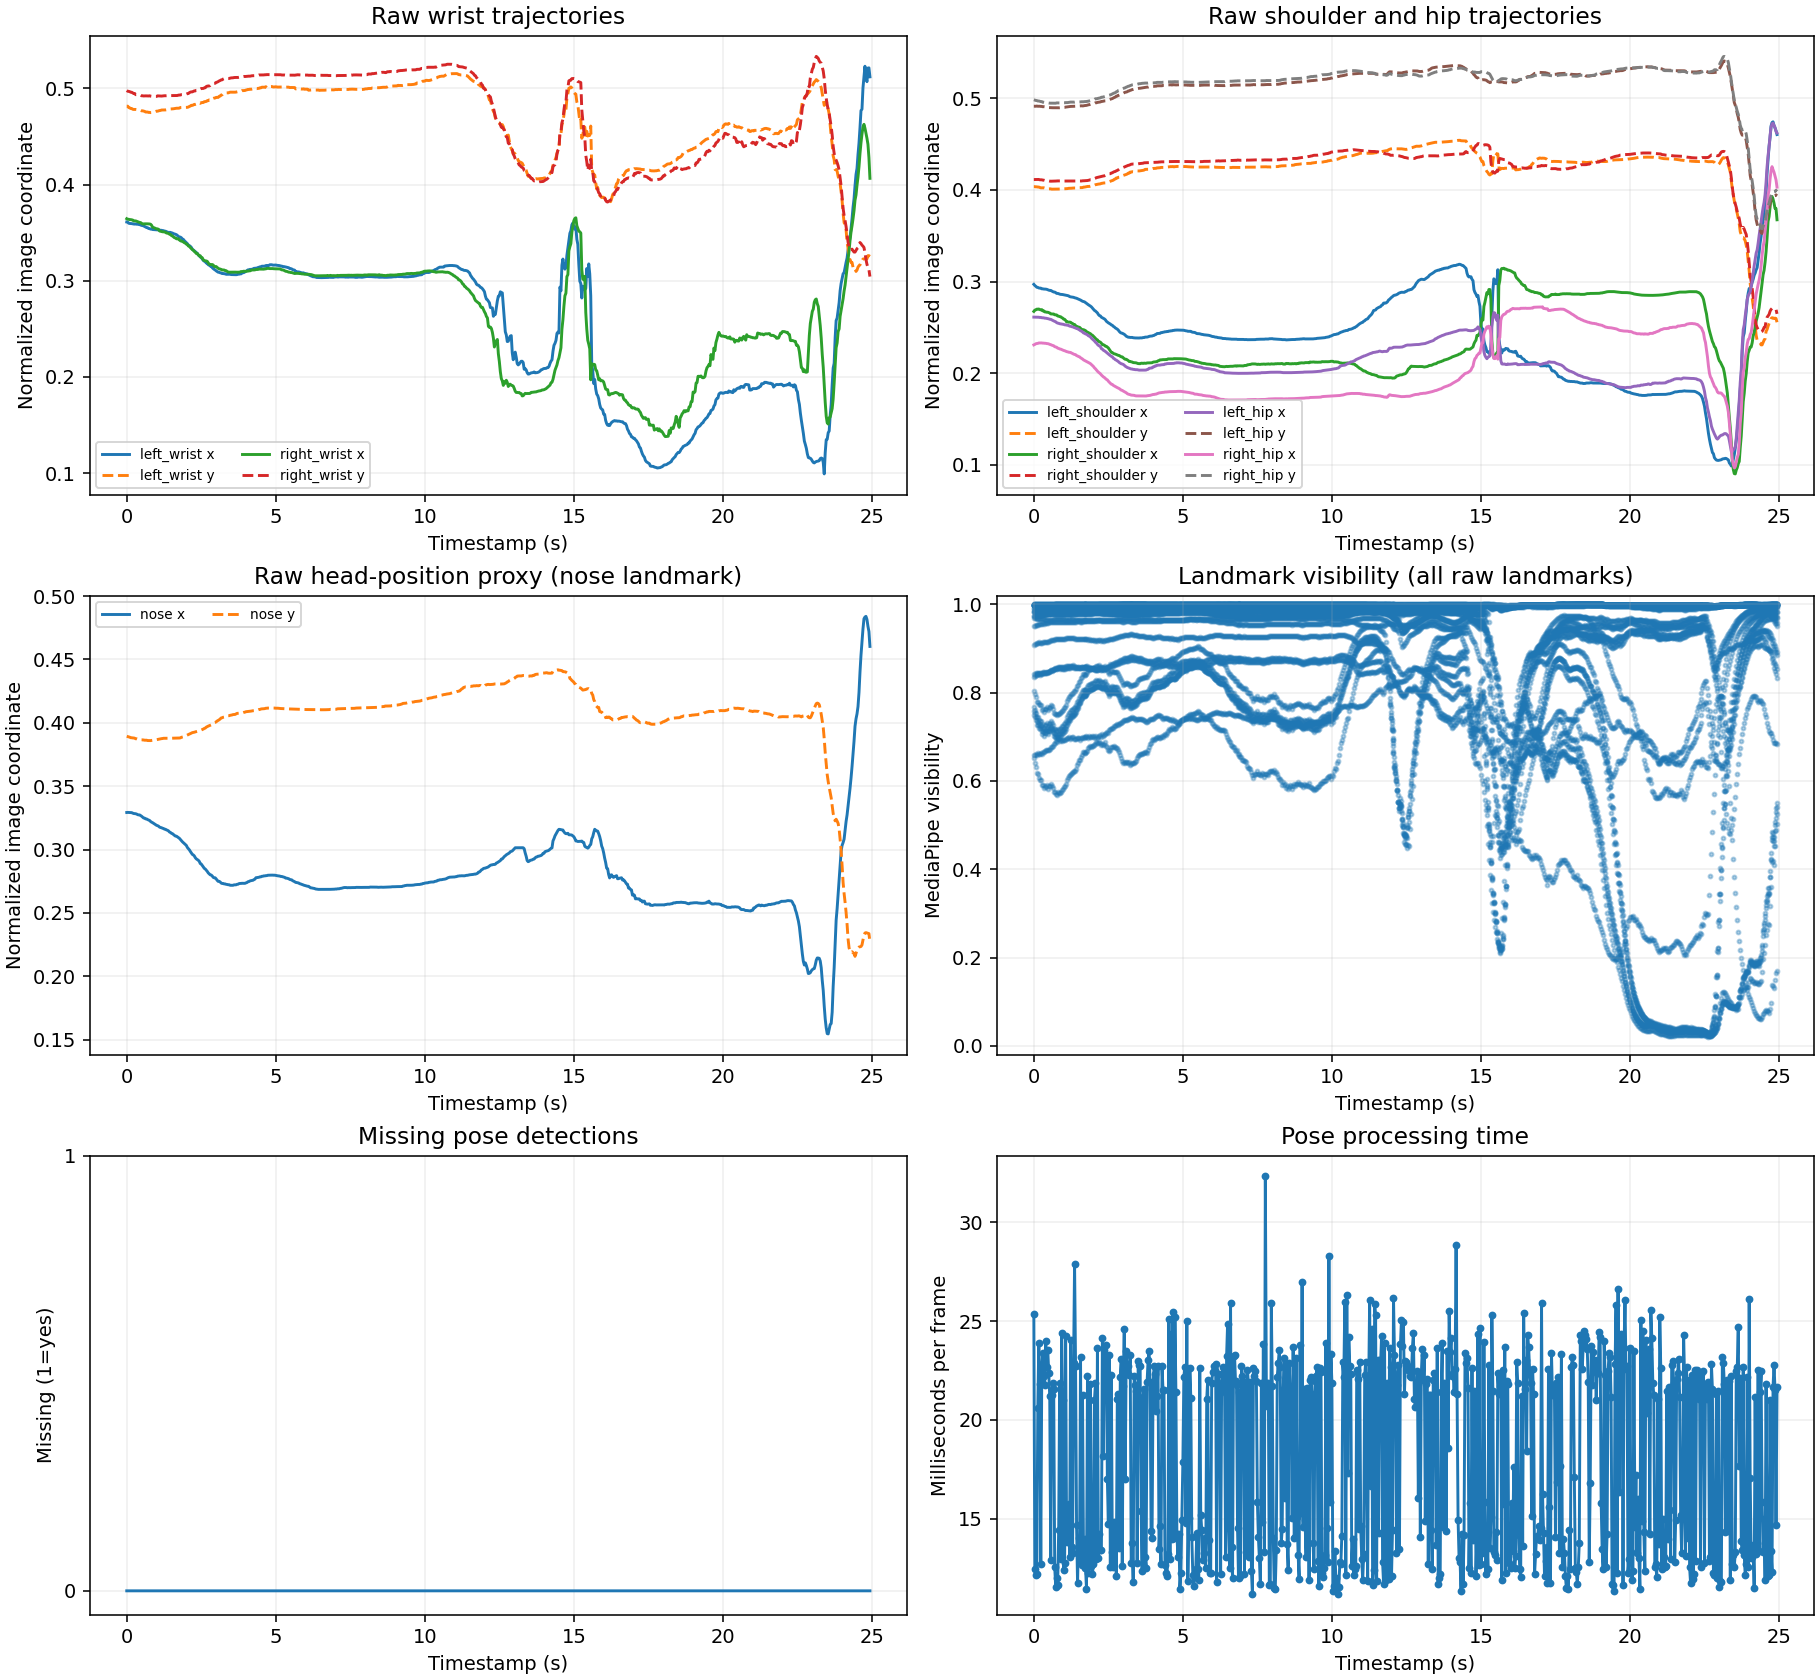

Consecutive missing-pose intervals: []
Largest landmark missing counts: [('nose', 0), ('left_eye_inner', 0), ('left_eye', 0), ('left_eye_outer', 0), ('right_eye_inner', 0), ('right_eye', 0), ('right_eye_outer', 0), ('left_ear', 0)]


In [5]:
display(Image(filename=str(pose_paths.plots_png)))
print('Consecutive missing-pose intervals:', [item.model_dump() for item in summary.missing_pose_intervals])
print('Largest landmark missing counts:', sorted(summary.missing_landmark_counts_by_name.items(), key=lambda item: item[1], reverse=True)[:8])

## Annotated side-by-side video and illustrative frames

The three source indexes below were chosen manually after viewing this clip. They are illustrative address/start, approximate top, and follow-through frames; no event detector selected them.

In [6]:
manual_frames = {'address/start (illustrative)': 272, 'approximate top (illustrative)': 408, 'follow-through (illustrative)': 544}
available = {frame.frame_index for frame in ingestion.frames}
if not set(manual_frames.values()).issubset(available):
    count = len(ingestion.frames)
    manual_frames = {
        'address/start (illustrative)': ingestion.frames[count // 4].frame_index,
        'approximate top (illustrative)': ingestion.frames[count // 2].frame_index,
        'follow-through (illustrative)': ingestion.frames[(3 * count) // 4].frame_index,
    }
start = min(manual_frames.values()) - 20
stop = max(manual_frames.values()) + 21
video_frames = tuple(frame for frame in ingestion.frames if start <= frame.frame_index < stop)
video_indexes = {frame.frame_index for frame in video_frames}
video_observations = tuple(row for row in pose_result.observations if row.frame_index in video_indexes)
annotated = write_annotated_video(
    sample_video, video_frames, video_observations, workspace / 'raw_and_annotated.mp4', side_by_side=True
)
print(annotated)
display(Video(filename=str(annotated.path), embed=False, html_attributes='controls'))

AnnotatedVideoResult(path=PosixPath('/tmp/osa-pose-notebook-o88bxpqd/raw_and_annotated.mp4'), frame_count=313, width_px=2160, height_px=1920, side_by_side=True, codec='libx264')


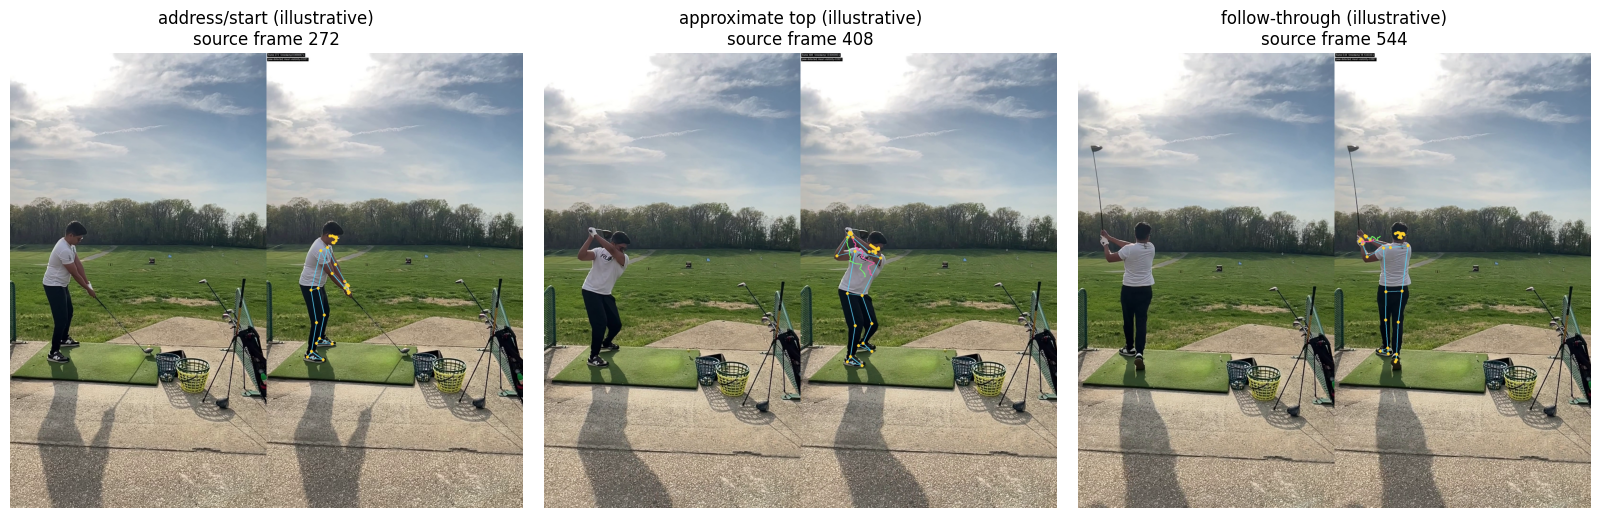

In [7]:
positions = {source_index - start: label for label, source_index in manual_frames.items()}
selected = list(VideoReader(annotated.path).iter_frames(FrameSelection(indices=frozenset(positions))))
fig, axes = plt.subplots(1, len(selected), figsize=(16, 5), constrained_layout=True)
for axis, frame in zip(axes, selected, strict=True):
    source_index = frame.frame_index + start
    axis.imshow(frame.image)
    axis.set_title(f'{positions[frame.frame_index]}\nsource frame {source_index}')
    axis.axis('off')
plt.show()

## Performance and scope

In [8]:
fps = summary.frames_processed / summary.total_inference_time_s if summary.total_inference_time_s else None
print(f'CPU inference: {summary.total_inference_time_s:.3f} s total; {summary.mean_processing_time_ms:.3f} ms/frame; {fps:.2f} frames/s')
print(f'Pose coverage: {summary.frames_with_pose}/{summary.frames_processed} ({summary.pose_detection_coverage:.1%})')
print('Raw observations remain unchanged; overlays were drawn from the stored rows.')
print('No smoothing, event detection, physical-angle inference, or coaching was performed.')
print('EXECUTED_OK')

CPU inference: 13.537 s total; 18.074 ms/frame; 55.33 frames/s
Pose coverage: 749/749 (100.0%)
Raw observations remain unchanged; overlays were drawn from the stored rows.
No smoothing, event detection, physical-angle inference, or coaching was performed.
EXECUTED_OK
